Etapa 1: Contextualização e Formulação da Pergunta

O dataset usado para o nosso modelo é o 'songs_normalize.csv' do spotify, disponível no site Kaggle, sendo o nosso contexto temático o mundo da música e a análise de variadas
músicas conhecidas e escutadas na plataforma. Nosso problema busca avaliar o quanto a música é dançável a partir da análise dos valores que cada música tem em cada tópico(coluna).
A relevância dele é justamente no foco de avaliar e descobrir mais a fundo sobre características daquela música que você mais gosta de escutar. 

A variável alvo é 'danceability', que mede o quanto uma música é adequada para dançar, com base em elementos musicais como ritmo, regularidade do compasso, força da batida e 
estabilidade do tempo. Varia de 0 (pouco dançável) a 1 (muito dançável).

As variáveis de entrada são:
energy (0 a 1): intensidade e atividade percebida. Músicas rápidas, altas e barulhentas têm valores altos; as calmas, valores baixos.
valence (0 a 1): positividade musical transmitida. Valores altos indicam sons alegres e otimistas; valores baixos, sons tristes ou sombrios.
speechiness (0 a 1): presença de palavras faladas na faixa. Valores altos indicam fala predominante, como rap ou podcasts; valores baixos, pouca ou nenhuma fala.
acousticness (0 a 1): confiança de que a faixa é acústica, ou seja, feita com instrumentos não eletrônicos. Valores altos indicam som acústico.
instrumentalness (0 a 1): probabilidade de a faixa não ter vocais. Valores próximos de 1 indicam música instrumental.
liveness (0 a 1): probabilidade de a gravação ter sido feita ao vivo, com presença de público. Valores acima de 0,8 indicam forte presença de plateia.
Todas são medidas numéricas contínuas entre 0 e 1, que vai facilitar a comparação entre elas.

O nosso problema analítico exige uma abordagem de Regressão, já que o que será analisado é: 'O que faz uma música ter uma alta danceability?'
E nesse caso ela iria prever o quanto a música(x) tem de danceability.

Ela é uma grandeza numérica contínua, medida em uma escala de 0 a 1, e pode assumir qualquer valor nesse intervalo, como 0,613 ou 0,847. O objetivo do modelo é justamente
estimar esse valor com precisão a partir das características da música.

A classificação, por outro lado, é indicada quando a saída do modelo pertence a um conjunto finito de categorias, como “dançável” ou “não dançável”. Nesse caso, a informação numérica seria descartada e o modelo perderia a gradação entre músicas pouco e muito dançáveis. Portanto, o uso da regressão se dá, justamente, pelo modelo prever um valor e não apenas
verificar se algo é ou não é(resposta com valores do df)

In [ ]:

pip install pandas numpy matplotlib seaborn scikit-learn

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Etapa 2: Exploração e Engenharia de Dados

In [ ]:
df=pd.read_csv('songs_normalize.csv')
display(df.head()) #baixando o df e exibindo-o

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


In [ ]:
print("Linhas e colunas:", df.shape)
print(df.dtypes) #print dos tipos de cada dado da tabela

Linhas e colunas: (2000, 18)
artist                  str
song                    str
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                   str
dtype: object


In [ ]:
print(df.isnull().sum()) #verificando valores nulos em cada coluna

artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64


In [ ]:
print("Linhas duplicadas:", df.duplicated().sum()) #verificando se tem a existência de linhas duplicadas no df

Linhas duplicadas: 59


In [ ]:
df = df.drop_duplicates() #excluindo as linhas duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 0


In [ ]:
X = df.drop(columns=['popularity'])
y = df['popularity']
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape) #dimensionando X e Y de acordo com os dados a serem estudados

Dimensões de X: (1941, 17)
Dimensões de y: (1941,)


Etapa 3: Particionamento dos Dados (Treino e Teste)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Dados de treino:', X_train.shape[0])
print('Dados de teste:', X_test.shape[0]) #separando em dados de teste e dados de treino

Dados de treino: 1552
Dados de teste: 389


Etapa 4: Construção e Treinamento do Modelo

In [82]:

modelo = LinearRegression() #extraindo e inspecionando os coeficientes angulares e o intercepto linear
modelo.fit(X_train, y_train)
print("Intercepto:", modelo.intercept_)
coeficientes = pd.DataFrame({
    'Variável': X.columns,
    'Coeficiente': modelo.coef_
})
display(coeficientes.sort_values(by='Coeficiente', key=abs, ascending=False))


Intercepto: -18.675417672874808


,Variável,Coeficiente
725,artist_T-Pain,-44.581643
35,artist_Adele,-35.944993
688,artist_Shayne Ward,-35.161382
97,artist_Basement Jaxx,-34.599580
368,artist_Jay Sean,-34.577482
...,...,...
2465,song_There You Go,0.000000
2471,song_This Ain't a Love Song,0.000000
2039,song_Paralyzer,0.000000
2040,song_Paris,0.000000


Etapa 5: Avaliação Quantitativa e Diagnóstico Visual

R²: -0.0190
MAE: 15.0974
RMSE: 22.6259


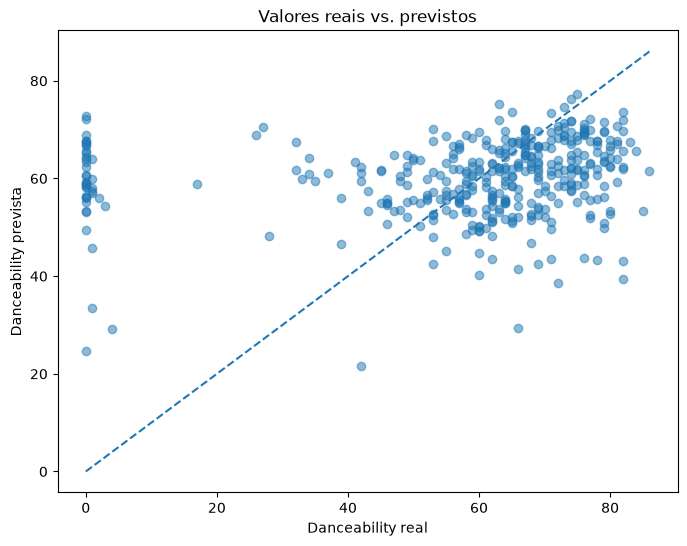

In [ ]:
#calculando as métricas e construindo o gráfico de dispersão (valores reais e valores previstos)
features_chave = ['energy', 'valence', 'speechiness', 'acousticness','instrumentalness', 'liveness']
X_chave = df[features_chave].astype(float)
y_chave = df['danceability']
y_previsto = modelo.predict(X_test) 
r2 = r2_score(y_test, y_previsto)
mae = mean_absolute_error(y_test, y_previsto)
rmse = np.sqrt(mean_squared_error(y_test, y_previsto))
print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_previsto, alpha=0.5)

limite_min = min(y_test.min(), y_previsto.min())
limite_max = max(y_test.max(), y_previsto.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--'
)

plt.xlabel('Danceability real')
plt.ylabel('Danceability prevista')
plt.title('Valores reais vs. previstos')
plt.show()

Etapa 6: Simulador Interativo (Inferência com Entrada do Usuário)

In [ ]:
energia = float(input('Energia (0 a 1): '))
valencia = float(input('Positividade (0 a 1): '))
fala = float(input('Presença de fala (0 a 1): '))
acustica = float(input('Grau acústico (0 a 1): '))
instrumental = float(input('Ausência de voz (0 a 1): '))
vivacidade = float(input('Presença de público (0 a 1): '))

dados_musica = {
    'energy': energia,
    'valence': valencia,
    'speechiness': fala,
    'acousticness': acustica,
    'instrumentalness': instrumental,
    'liveness': vivacidade}

df_musica = pd.DataFrame([dados_musica])[features_chave]
danceability_estimada = min(1, max(0, modelo_chave.predict(df_musica)[0]))

print(f'Danceability estimada: {danceability_estimada:.2f} (escala de 0 a 1)')

Etapa 7: Discussão Crítica e Conclusões


1. Interpretação das Métricas: O que os resultados numéricos revelam sobre a
eficácia prática do modelo? Ele é confiável para tomada de decisão real?

O modelo apresentou R^2 de 0,2532, MAE de 0,0977 e o RMSE de 0,1245, mostrando que existem diferenças entre os valores reais e previstos. Portanto, o modelo possui capacidade limitada de previsão e precisa ser aprimorado antes de ser utilizado em decisões reais.

2. Diagnóstico dos Erros:

○ Caso Regressão: A diferença entre MAE e RMSE aponta presença de
desvios atípicos acentuados? O que o peso de cada variável revela sobre a
importância delas?

O RMSE foi superior ao MAE, sugerindo que alguns erros maiores influenciam o desempenho do modelo. Os coeficientes da Regressão Linear permitem analisar como cada variável influencia as previsões, identificando associações positivas ou negativas com a dançabilidade.

3. Limitações: Quais fatores ou variáveis adicionais não presentes na sua base
original poderiam elevar a precisão do sistema se estivessem disponíveis?

A precisão do modelo poderia melhorar com a inclusão de outras características musicais, como ritmo, estrutura da música, padrões de batida e informações sobre a percepção dos ouvintes. Além disso, outros algoritmos poderiam ser testados para comparar os resultados e buscar previsões mais precisas.